In [ ]:
# Shared bootstrap for notebooks organized by world.
from pathlib import Path
import os, sys
_here = Path.cwd().resolve()
_roots = ( _here, *_here.parents )
_root = next((p for p in _roots if (p / 'pyproject.toml').is_file() and (p / 'src').is_dir()), None)
if _root is None: raise FileNotFoundError('Launch Jupyter from inside the research repository')
if str(_root) not in sys.path: sys.path.insert(0, str(_root))
os.chdir(_root / 'notebooks')  # preserve paths from older notebooks
print('Repository root:', _root)


## Medium-world learnability diagnostics
Read diagnostic outputs, compare model behavior and inspect shortcuts.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path().cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
OUT = PROJECT_ROOT / "outputs/medium_world/experiments/diagnostics"

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

### 1. Training versus development

In [2]:
path = OUT / "train_vs_dev.json"
if path.is_file():
    rows = []
    for run in read_json(path)["runs"]:
        for split in ("train", "id_dev"):
            for task, score in run[split]["by_template"].items():
                rows.append({"seed": run["seed"], "schedule": run["schedule"],
                             "split": split, "task": task, "accuracy": score})
    scores = pd.DataFrame(rows)
    display(scores.groupby(["schedule", "split", "task"])["accuracy"].mean().unstack("split"))
else:
    print("Run evaluate_training_set.py first")

split                   id_dev    train
schedule task                          
mixed    color        0.830469  0.83128
         conjunction  0.703125  0.68584
         pair         0.526563  0.52424
         shape        0.525000  0.52320
reverse  color        0.825000  0.83152
         conjunction  0.693750  0.69104
         pair         0.514062  0.51496
         shape        0.536719  0.53416
staged   color        0.950781  0.94384
         conjunction  0.766406  0.74816
         pair         0.513281  0.51760
         shape        0.530469  0.54288

### 2. Single-task memorization and generalization

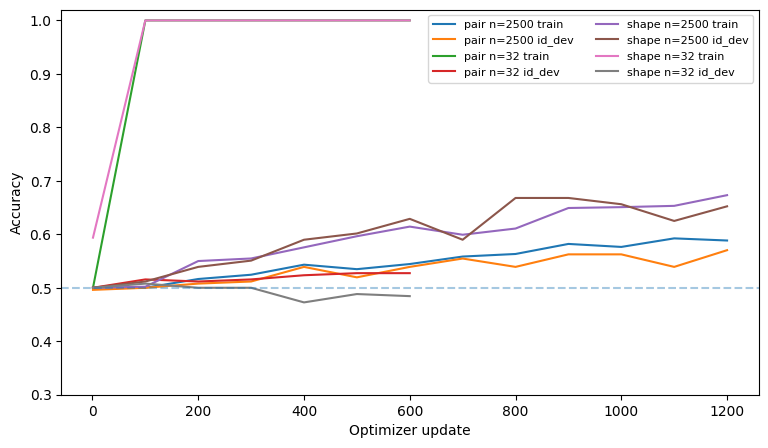

In [3]:
files = sorted((OUT / "single_task").glob("*.json"))
if files:
    fig, ax = plt.subplots(figsize=(9, 5))
    for path in files:
        run = read_json(path)
        steps = [item["step"] for item in run["history"]]
        for split in ("train", "id_dev"):
            scores = [item[split]["accuracy"] for item in run["history"]]
            ax.plot(steps, scores, label=f"{run['task']} n={run['subset']} {split}")
    ax.axhline(0.5, linestyle="--", alpha=0.4)
    ax.set(xlabel="Optimizer update", ylabel="Accuracy", ylim=(0.3, 1.02))
    ax.legend(fontsize=8, ncol=2)
    plt.show()
else:
    print("Run train_single_task.py first")

### 3. Conjunction and binding shortcuts

,count,accuracy,predicted_positive_rate
conjunction/negative_missing_color,76,1.000000,0.000000
conjunction/negative_missing_shape,52,0.250000,0.750000
conjunction/positive_both_present,128,0.851562,0.851562
pair/negative_hard_pair,128,0.968750,0.031250
pair/positive_pair_present,128,0.031250,0.031250


,count,accuracy,predicted_positive_rate
conjunction/circle,64,0.796875,0.546875
conjunction/crescent,64,0.828125,0.390625
conjunction/square,64,0.765625,0.671875
conjunction/triangle,64,0.703125,0.703125
pair/circle,66,0.500000,0.000000
pair/crescent,66,0.500000,0.030303
pair/square,60,0.516667,0.016667
pair/triangle,64,0.484375,0.078125


,count,accuracy,predicted_positive_rate
color_only,256,0.796875,0.703125
shape_only,256,0.703125,0.796875


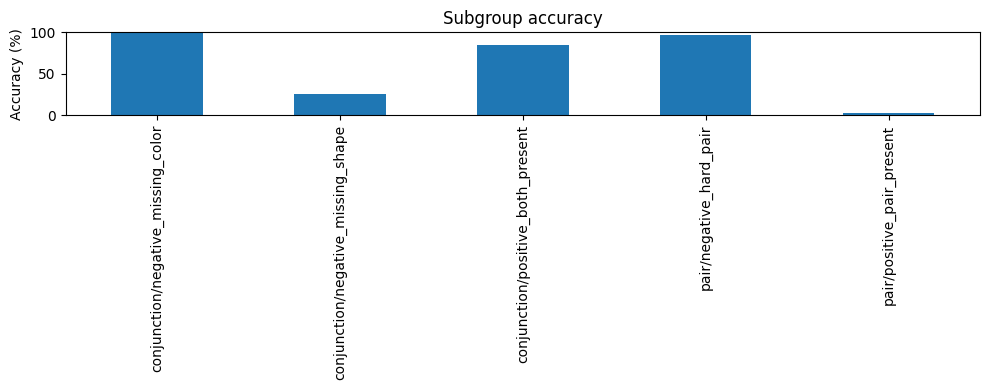

In [4]:
path = OUT / "question_shortcuts.json"
if path.is_file():
    report = read_json(path)
    subgroup = pd.DataFrame.from_dict(report["subgroups"], orient="index")
    display(subgroup)
    display(pd.DataFrame.from_dict(report["target_shape"], orient="index"))
    display(pd.DataFrame.from_dict(report["conjunction_baselines"], orient="index"))
    subgroup["accuracy"].mul(100).plot(kind="bar", figsize=(10, 4), ylim=(0, 100),
                                        ylabel="Accuracy (%)", title="Subgroup accuracy")
    plt.tight_layout()
    plt.show()
else:
    print("Run diagnose_question_shortcuts.py first")

### 4. Questions to resolve
- Can the model fit 32 shape examples?
- Does shape dev accuracy improve when trained alone?
- Can the model fit hard-negative pair questions?
- Does conjunction performance exceed the color-only baseline?
- Only then: does more curriculum training improve binding?